In [10]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

In [2]:
# read in all the words
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [3]:
len(words)

32033

In [4]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [7]:
# build the dataset
block_size = 3

def build_dataset(words):  #context length: how many characters we take to predict the next one
  X, Y = [], []
  for w in words:

    #print(w)
    context = [0] * block_size # pad "." before word
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix] # rolling context

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  # print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
k1 = int(0.8*len(words))
k2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:k1])
Xeval, Yeval = build_dataset(words[k1:k2])
Xte, Yte = build_dataset(words[k2:])

In [38]:
# initialize configs
n_embed = 10 # dimensionality of character-embedding vectors
n_hidden = 200 # number of neurons in hidden layer of MLP

g = torch.Generator().manual_seed(21391991)

C = torch.randn((vocab_size, n_embed), generator=g) # two-dimensional gradient for each of the letters, NxD
W1 = torch.randn((block_size*n_embed, n_hidden), generator=g) * (5/3)/((n_embed*block_size)**0.5) # Kaiming Init
# b1 = torch.randn((n_hidden), requires_grad=True, generator=g)
W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.01
b2 = torch.randn((vocab_size), generator=g) * 0

# initialize Scale and Shift, but change nothing before backprop
bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros((1, n_hidden))

bnmean_running = torch.zeros((1, n_hidden))
bnstd_running = torch.ones((1, n_hidden))

# bundle together for easier backward pass
parameters = [C, W1, W2, b2, bngain, bnbias]
for p in parameters:
    p.requires_grad = True

In [39]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

  # forward pass
  emb = C[Xb] # embed the characters into vectors
  embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
  # Linear layer
  hpreact = embcat @ W1 #+ b1 # hidden layer pre-activation

  # BatchNorm
  bnmeani = hpreact.mean(0, keepdim=True)
  bnstdi = hpreact.std(0, keepdim=True)
  hpreact = bngain * (hpreact - bnmeani) / bnstdi + bnbias

  with torch.no_grad():
    bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
    bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi

  # Non-linearity
  h = torch.tanh(hpreact) # hidden layer
  logits = h @ W2 + b2 # output layer
  loss = F.cross_entropy(logits, Yb) # loss function

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())


      0/ 200000: 3.2910
  10000/ 200000: 1.7731
  20000/ 200000: 2.6376
  30000/ 200000: 2.0541
  40000/ 200000: 2.4522
  50000/ 200000: 2.0553
  60000/ 200000: 2.4679
  70000/ 200000: 1.6663
  80000/ 200000: 1.9181
  90000/ 200000: 2.1654
 100000/ 200000: 2.2263
 110000/ 200000: 2.3938
 120000/ 200000: 2.3816
 130000/ 200000: 1.8530
 140000/ 200000: 1.9910
 150000/ 200000: 2.0734
 160000/ 200000: 2.0231
 170000/ 200000: 1.9591
 180000/ 200000: 2.0656
 190000/ 200000: 2.3548


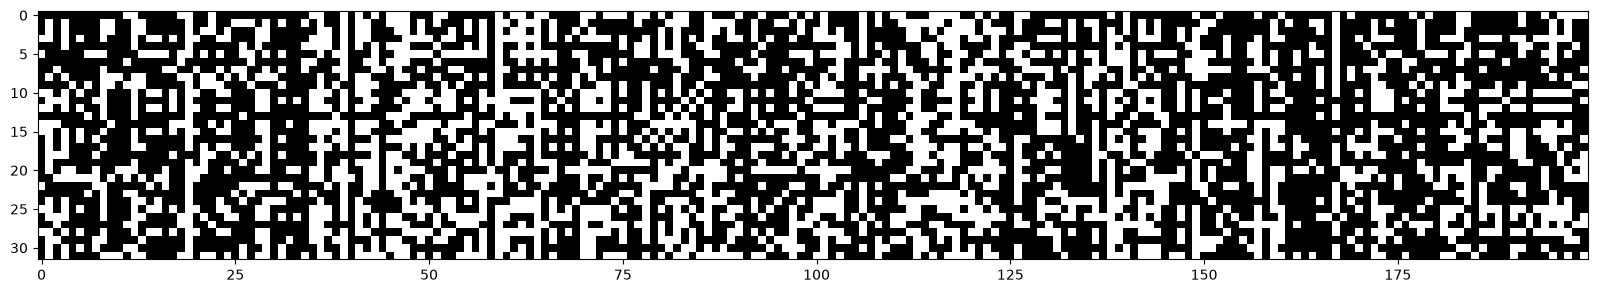

In [20]:
plt.figure(figsize=(20, 10))
plt.imshow(h.abs()>0.99, cmap="gray", interpolation="nearest")

# each column is a neuron. So if a column is entirely white, it is basically dead

(array([1717.,  341.,  185.,  142.,   95.,   75.,   86.,   52.,   38.,
          43.,   34.,   37.,   31.,   22.,   44.,   36.,   41.,   31.,
          26.,   24.,   34.,   20.,   26.,   27.,   28.,   21.,   25.,
          23.,   32.,   24.,   27.,   23.,   29.,   36.,   24.,   29.,
          31.,   26.,   39.,   38.,   47.,   40.,   49.,   59.,   84.,
         121.,  122.,  154.,  264., 1798.]),
 array([-1.  , -0.96, -0.92, -0.88, -0.84, -0.8 , -0.76, -0.72, -0.68,
        -0.64, -0.6 , -0.56, -0.52, -0.48, -0.44, -0.4 , -0.36, -0.32,
        -0.28, -0.24, -0.2 , -0.16, -0.12, -0.08, -0.04,  0.  ,  0.04,
         0.08,  0.12,  0.16,  0.2 ,  0.24,  0.28,  0.32,  0.36,  0.4 ,
         0.44,  0.48,  0.52,  0.56,  0.6 ,  0.64,  0.68,  0.72,  0.76,
         0.8 ,  0.84,  0.88,  0.92,  0.96,  1.  ]),
 <BarContainer object of 50 artists>)

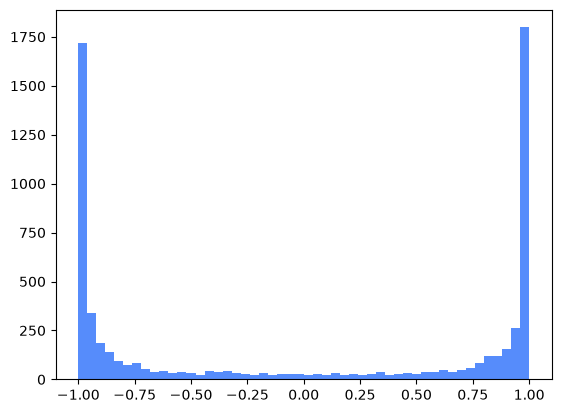

In [21]:
plt.hist(h.view(-1).tolist(), 50)
# view distribution of weights pre-tanh, pre-normalization

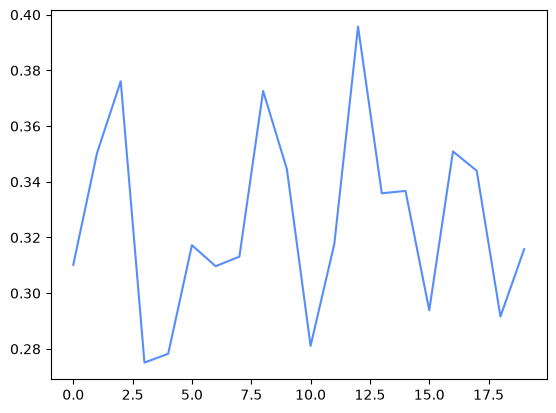

In [34]:
plt.plot(lossi)

In [36]:
# calibrate batchnorm at end of training - important because now we can pass in a single value as input to test (previously required batch because of calculating batch norm)

# but nobody want to do the extra step lol, but we can estimate over entire dataset during training
with torch.no_grad():
  # pass the training set through
  emb = C[Xtr]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 # + b1
  # measure the mean/std over the entire training set
  bnmean = hpreact.mean(0, keepdim=True)
  bnstd = hpreact.std(0, keepdim=True)

In [40]:
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xeval, Yeval),
    'test': (Xte, Yte),
  }[split]
  emb = C[x] # (N, block_size, n_embd)
  embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
  hpreact = embcat @ W1 # + b1
  # hpreact = bngain * (hpreact - hpreact.mean(0, keepdim=True)) / hpreact.std(0, keepdim=True) + bnbias
  hpreact = bngain * (hpreact - bnmean_running) / bnstd_running + bnbias
  h = torch.tanh(hpreact) # (N, n_hidden)
  logits = h @ W2 + b2 # (N, vocab_size)
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.068880081176758
val 2.1107449531555176


## Logs:

### original:
train 2.0634877681732178
val 2.126756191253662

### add batchnorm:
train 2.0533955097198486
val 2.1037604808807373